# 03 — Segment Analysis (Bonferroni-corrected)

In [1]:
import os
import sys
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import pandas as pd

if Path.cwd().name == "notebooks":
    os.chdir("..")
sys.path.insert(0, str(Path.cwd()))

from src.stats_utils import analyze_segment

con = duckdb.connect("data/processed/ab_test.duckdb", read_only=True)
Path("reports/figures").mkdir(parents=True, exist_ok=True)

def run_query(path):
    """Jalankan satu file SQL dan return hasilnya sebagainya dataFrame"""
    return con.sql(Path(path).read_text()).df()


overall = run_query("sql/03_conversion_by_group.sql").set_index("test_group")
p_control = overall.loc["psa", "n_converted"] / overall.loc["psa", "n_users"]
p_treat = overall.loc["ad", "n_converted"] / overall.loc["ad", "n_users"]
overall_lift_pp = (p_treat - p_control) * 100
print(f"Overall lift: {overall_lift_pp:.3f} pp")

Overall lift: 0.769 pp


In [2]:
def plot_segment_lift(res, segment_col, title, filename):
    """Forest plot: lift per segment with Bonferroni-adjusted CI."""
    fig, ax = plt.subplots(figsize=(8, 0.35 * len(res) + 1.5))
    
    
    for i, row in enumerate(res.itertuples()):
        color = "tab:green" if row.significant else "tab:gray"
        ax.errorbar(
            row.abs_lift_pp, i,
            xerr=[[row.abs_lift_pp - row.ci_low_pp], [row.ci_high_pp - row.abs_lift_pp]],
            fmt="o", color=color, capsize=3,
        )
    
    ax.axvline(0, color="black", linewidth=1)
    ax.axvline(overall_lift_pp, color="red", linestyle=":",
               label=f"Overall lift ({overall_lift_pp:.2f} pp)")
    ax.set_yticks(range(len(res)))
    ax.set_yticklabels(res[segment_col].astype(str))
    ax.invert_yaxis()
    ax.set_xlabel("Absolute lift (pp), Bonferroni-adjusted CI")
    ax.set_title(title)
    ax.legend(loc="best")
    plt.tight_layout()
    plt.savefig(f"reports/figures/{filename}", dpi=150, bbox_inches="tight")
    plt.show()

,most_ads_day,n_ad,n_psa,x_psa,cr_ad_pct,cr_psa_pct,abs_lift_pp,ci_low_pp,ci_high_pp,p_value,p_bonferroni,significant,mde_pp
0,Monday,83571,3502,79,3.3241,2.2559,1.0683,0.3729,1.7636,0.0005,0.0036,True,0.8067
1,Tuesday,74572,2907,42,3.0440,1.4448,1.5992,0.9803,2.2182,0.0000,0.0000,True,0.8842
2,Wednesday,77418,3490,55,2.5356,1.5759,0.9597,0.3725,1.5468,0.0004,0.0026,True,0.8093
3,Thursday,79077,3905,79,2.1637,2.0230,0.1407,-0.4812,0.7625,0.5548,1.0000,False,0.7667
4,Friday,88805,3803,62,2.2465,1.6303,0.6162,0.0478,1.1846,0.0116,0.0810,False,0.7744
5,Saturday,78802,2858,40,2.1307,1.3996,0.7311,0.1240,1.3382,0.0075,0.0524,False,0.8905
6,Sunday,82332,3059,63,2.4620,2.0595,0.4025,-0.3034,1.1084,0.1572,1.0000,False,0.8611


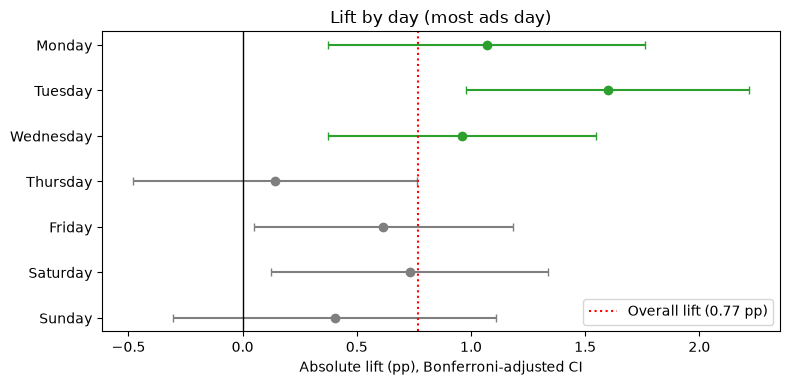

In [3]:
seg_day = run_query("sql/04_segment_by_day.sql")
res_day = analyze_segment(seg_day, "most_ads_day", p_baseline=p_control)
display(res_day.round(4))
plot_segment_lift(res_day, "most_ads_day", "Lift by day (most ads day)", "segment_day.png")

,most_ads_hour,n_ad,n_psa,x_psa,cr_ad_pct,cr_psa_pct,abs_lift_pp,ci_low_pp,ci_high_pp,p_value,p_bonferroni,significant,mde_pp
0,0,5309,227,0,1.9213,0.0000,1.9213,1.3414,2.5012,0.0350,0.8410,False,3.5180
1,1,4615,187,0,1.3434,0.0000,1.3434,0.8218,1.8651,0.1106,1.0000,False,3.8718
2,2,5152,181,0,0.7570,0.0000,0.7570,0.3853,1.1287,0.2401,1.0000,False,3.9253
3,3,2590,89,1,1.0425,1.1236,-0.0811,-3.5746,3.4124,0.9410,1.0000,False,5.5957
4,4,694,28,0,1.5850,0.0000,1.5850,0.1257,3.0443,0.5020,1.0000,False,10.0051
5,5,742,23,0,2.1563,0.0000,2.1563,0.5150,3.7977,0.4766,1.0000,False,10.9894
6,6,1985,83,0,2.3174,0.0000,2.3174,1.2779,3.3568,0.1607,1.0000,False,5.8152
7,7,6168,237,2,1.8482,0.8439,1.0044,-0.8993,2.9080,0.2552,1.0000,False,3.4358
8,8,16968,659,7,1.9861,1.0622,0.9239,-0.3488,2.1965,0.0925,1.0000,False,2.0608
9,9,29802,1202,13,1.9529,1.0815,0.8714,-0.0795,1.8222,0.0309,0.7407,False,1.5270


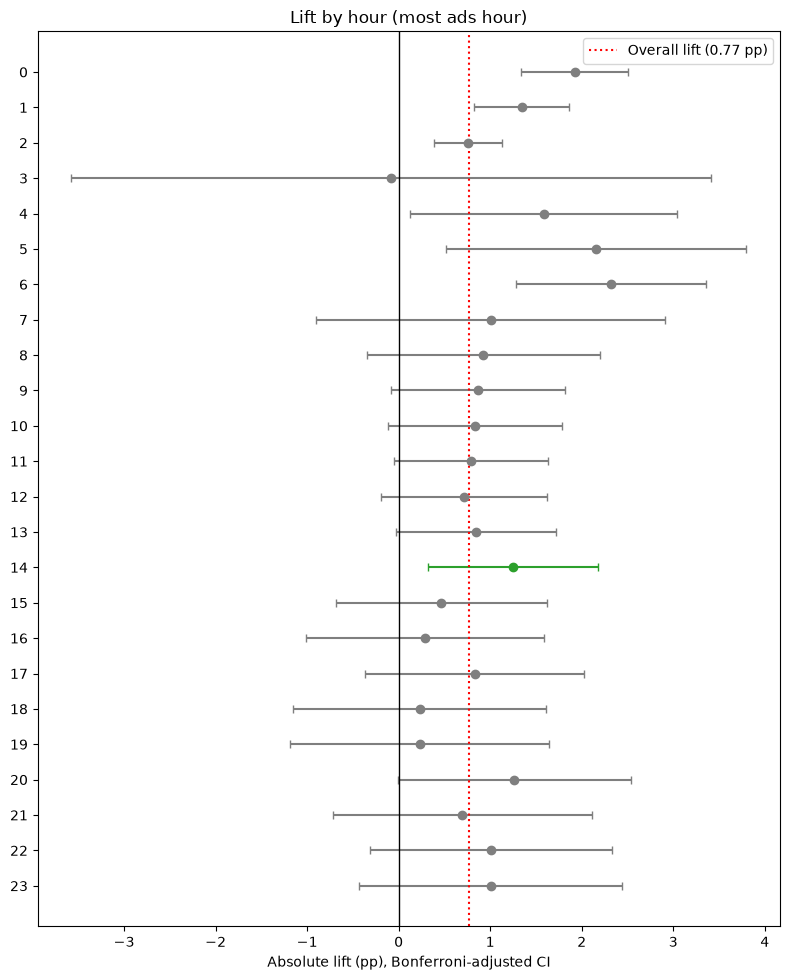

In [4]:
seg_hour = run_query("sql/05_segment_by_hour.sql")
res_hour = analyze_segment(seg_hour, "most_ads_hour", p_baseline=p_control)
display(res_hour.round(4))
plot_segment_lift(res_hour, "most_ads_hour", "Lift by hour (most ads hour)", "segment_hour.png")

,ads_bin,min_ads,max_ads,n_ad,n_psa
0,1,1,3,119537,5557
1,2,4,8,106476,4794
2,3,9,17,117250,3984
3,4,18,33,109099,4530
4,5,34,2065,112215,4659


,ads_range,n_ad,n_psa,x_psa,cr_ad_pct,cr_psa_pct,abs_lift_pp,ci_low_pp,ci_high_pp,p_value,p_bonferroni,significant,mde_pp
0,1-3,119537,5557,10,0.2125,0.1800,0.0325,-0.1179,0.1829,0.6054,1.0000,False,0.6210
1,4-8,106476,4794,26,0.3841,0.5423,-0.1582,-0.4358,0.1193,0.0859,0.4296,False,0.6681
2,9-17,117250,3984,29,0.7292,0.7279,0.0013,-0.3515,0.3541,0.9924,1.0000,False,0.7290
3,18-33,109099,4530,74,1.7186,1.6336,0.0851,-0.4105,0.5807,0.6657,1.0000,False,0.6862
4,34-2065,112215,4659,281,9.8293,6.0313,3.7980,2.8709,4.7251,0.0000,0.0000,True,0.6766


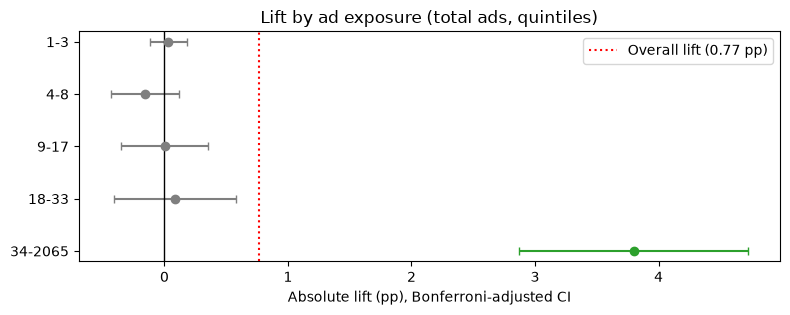

In [5]:
seg_ads = run_query("sql/06_segment_by_ads_quantile.sql")
display(seg_ads[["ads_bin", "min_ads", "max_ads", "n_ad", "n_psa"]])

seg_ads["ads_range"] = seg_ads["min_ads"].astype(str) + "-" + seg_ads["max_ads"].astype(str)
res_ads = analyze_segment(seg_ads, "ads_range", p_baseline=p_control)
display(res_ads.round(4))
plot_segment_lift(res_ads, "ads_range", "Lift by ad exposure (total ads, quintiles)", "segment_total_ads.png")

In [6]:
res_hour["enough_data"] = res_hour["x_psa"] >= 10
display(res_hour[["most_ads_hour", "n_psa", "x_psa", "abs_lift_pp", "p_value", "significant", "enough_data"]].round(4))

,most_ads_hour,n_psa,x_psa,abs_lift_pp,p_value,significant,enough_data
0,0,227,0,1.9213,0.0350,False,False
1,1,187,0,1.3434,0.1106,False,False
2,2,181,0,0.7570,0.2401,False,False
3,3,89,1,-0.0811,0.9410,False,False
4,4,28,0,1.5850,0.5020,False,False
5,5,23,0,2.1563,0.4766,False,False
6,6,83,0,2.3174,0.1607,False,False
7,7,237,2,1.0044,0.2552,False,False
8,8,659,7,0.9239,0.0925,False,False
9,9,1202,13,0.8714,0.0309,False,True


## Segment analysis — summary
All segment results are **exploratory**: segment variables were
measured during the experiment (post-treatment), so differences
between segments are not causal. Bonferroni correction is applied
within each family (day: m = 7, hour: m = 24, ad exposure: m = 5).
Segments with fewer than 10 control conversions are flagged as having
insufficient data (a common rule of thumb for the normal
approximation).

### By day
- Significant lift on Monday (1.07 pp), Tuesday (1.60 pp) and
  Wednesday (0.96 pp); not significant on other days.
- Friday and Saturday are borderline: their adjusted CIs barely
  exclude 0, but their p-values do not pass the Bonferroni threshold
  (the z-test uses a pooled SE, the CI an unpooled SE).
- Confidence intervals overlap across days, so this suggests, but does
  not prove, a stronger effect early in the week. Comparing days
  directly would require an interaction test.

### By hour
- Only hour 14 is significant after correction (p = 0.0013), with no
  consistent pattern across neighbouring hours.
- Without correction, 7 hours would appear significant (p < 0.05);
  after Bonferroni (α = 0.0021), only hour 14 remains. This shows how
  multiple testing inflates false positives.
- Hours 0–8 and 23 have very few control conversions (0–8), so the
  normal approximation is unreliable there; these hours are not
  interpreted.
- Among hours with enough data, the lift is positive in every hour,
  mostly 0.7–1.3 pp, close to the overall lift.
- Conclusion: the ad effect appears broadly positive throughout the
  day, but hourly data is too thin to distinguish one hour from
  another; there is no clear hour-of-day pattern.

### By ad exposure (total ads, quintiles)
- The lift is concentrated in the top quintile (34+ ads):
  9.83% vs 6.03%, +3.80 pp. In the other four quintiles (80% of
  users), the lift is near zero and the CIs rule out large effects.
- Conversion rises sharply with exposure in **both** groups, including
  the PSA group. `total ads` largely reflects user engagement, not
  just ad exposure.
- The data cannot tell whether ads work through repeated exposure or
  whether highly engaged users are simply more responsive. A follow-up
  experiment randomizing ad frequency would be needed to separate the
  two.